In [6]:
!pip3 install opencv-python lightning annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 2.7 MB/s eta 0:00:0000:0100:01
  Preparing metadata (setup.py) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp311-cp311-linux_x86_64.whl size=76814 sha256=2089da16a452be40beafa087749ae3faa1e3c0e0f89d94bbf2be1c791b65b4fb
  Stored in directory: /home/jovyan/.cache/pip/wheels/33/e5/58/0a3e34b92bedf09b4c57e37a63ff395ade6f6c1099ba59877c
Successfully built annoy


In [ ]:
import os
import shutil
import pandas as pd
from glob import glob
from tqdm.notebook import tqdm
import numpy as np
from PIL import Image, ImageOps, ImageFilter
import cv2
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from skimage import io
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances
import math
import torch
from torch import nn
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision import tv_tensors
from torchvision.transforms import v2 as T
import torchvision.transforms as transforms
import lightning as L
from annoy import AnnoyIndex
from collections import Counter

## Segmentation model

In [25]:
def clean_background(src):
    tmp = cv2.cvtColor(src, cv2.COLOR_BGR2GRAY)
    _, alpha = cv2.threshold(tmp, 0, 255, cv2.THRESH_BINARY)
    b, g, r = cv2.split(src)
    rgba = [b, g, r, alpha]
    dst = cv2.merge(rgba, 4)
    return dst


def get_model_instance_segmentation(num_classes, pre_trained: bool):
    # load an instance segmentation model pre-trained on COCO
    if pre_trained:
        model = torchvision.models.detection.maskrcnn_resnet50_fpn_v2(weights="COCO_V1")
    else:
        model = torchvision.models.detection.maskrcnn_resnet50_fpn_v2()

    # get number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # now get the number of input features for the mask classifier
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    # and replace the mask predictor with a new one
    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        in_features_mask, hidden_layer, num_classes
    )
    return model


def get_transform(train):
    transforms = []
    if train:
        transforms.append(T.RandomPhotometricDistort(p=0.5))
        transforms.append(T.RandomAutocontrast(p=0.5))
        transforms.append(T.RandomAdjustSharpness(p=0.5, sharpness_factor=2))
        transforms.append(T.RandomHorizontalFlip(p=0.5))
        transforms.append(T.RandomVerticalFlip(p=0.5))
    transforms.append(T.ToDtype(torch.float32, scale=True))
    transforms.append(T.ToPureTensor())
    return T.Compose(transforms)


def get_transform_object():
    transforms = []
    transforms.append(T.RandomRotation(degrees=180))
    return T.Compose(transforms)

In [26]:
def extract_mask_images(
    path_to_model: str,
    output_dir: str,
    image_path: str,
    score_threshold: float,
    mask_threshold: float,
    name: str,
):
    device = torch.device("cpu")

    model = get_model_instance_segmentation(2, False)
    model.load_state_dict(torch.load(path_to_model, map_location=device))
    model.eval()

    image = Image.open(image_path).convert("RGB")
    image = tv_tensors.Image(image)

    eval_transform = get_transform(train=False)
    with torch.no_grad():
        x = eval_transform(image)
        # convert RGBA -> RGB and move to device
        x = x[:3, ...].to(device)
        predictions = model(
            [
                x,
            ]
        )
        pred = predictions[0]

    masks = pred["masks"].cpu().numpy()
    boxes = pred["boxes"].cpu().numpy()
    scores = pred["scores"].cpu().numpy()

    image = image.cpu().numpy()
    image = np.transpose(image, (1, 2, 0))

    extracted_objs = []

    for i in range(len(masks)):
        if scores[i] >= score_threshold:
            mask = masks[i, 0]
            box = boxes[i]

            extracted_obj = cv2.bitwise_and(
                image, image, mask=(mask > mask_threshold).astype(np.uint8)
            )
            extracted_obj = extracted_obj[
                int(box[1]) : int(box[3]), int(box[0]) : int(box[2])
            ]
            extracted_obj = clean_background(extracted_obj)

            output_path = os.path.join(output_dir, f'{name.split(".")[0]}_{i}.png')
            cv2.imwrite(output_path, extracted_obj)
            extracted_objs.append(extracted_obj)
    return extracted_objs

## Classification model

In [10]:
class OpenSetClassificationModel(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.num_classes = n_classes
        self.model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
        num_features = 384
        self.classifier = nn.Linear(num_features, n_classes, bias=True)
        self.anchors = nn.Parameter(torch.zeros(self.num_classes, self.num_classes).float(), requires_grad = False)

    def forward(self, x, skip_distance = False):
        batch_size = len(x)
        x = self.model(x)
        x = x.view(batch_size, -1)
        
        outLinear = self.classifier(x)
        outDistance = None if skip_distance else self.distance_classifier(outLinear)

        return outLinear, outDistance

    def distance_classifier(self, x):
        ''' Calculates euclidean distance from x to each class anchor
            Returns n x m array of distance from input of batch_size n to anchors of size m
        '''

        n = x.size(0)
        m = self.num_classes
        d = self.num_classes

        x = x.unsqueeze(1).expand(n, m, d).double()
        anchors = self.anchors.unsqueeze(0).expand(n, m, d)
        dists = torch.norm(x-anchors, 2, 2)

        return dists

    def set_anchors(self, means):
        self.anchors = nn.Parameter(means.float(), requires_grad = False)

In [11]:
class CACLoss(nn.Module):
    def __init__(self, num_known_classes, lbda=0.1):
        super().__init__()
        self.num_known_classes = num_known_classes
        self.lbda = lbda

    def forward(self, distances, gt):
        '''Returns CAC loss, as well as the Anchor and Tuplet loss components separately for visualisation.'''
        true = torch.gather(distances, 1, gt.view(-1, 1)).view(-1)
        non_gt = torch.Tensor([[i for i in range(self.num_known_classes) if gt[x] != i] for x in range(len(distances))]).long().cuda()
        others = torch.gather(distances, 1, non_gt)
    	
        anchor = torch.mean(true)
    
        tuplet = torch.exp(-others+true.unsqueeze(1))
        tuplet = torch.mean(torch.log(1+torch.sum(tuplet, dim = 1)))
    
        total = self.lbda*anchor + tuplet
    
        return total, anchor, tuplet

In [12]:
class PollenOSCEmbeddingsModule(L.LightningModule):
    def __init__(self,
                 n_classes,
                 alpha=10, # Magnitude of the anchor point
                 optim_lr=0.001,
                 optim_betas=(0.9, 0.999),
                 optim_eps=1e-08,
                 optim_weight_decay=0.01,
                 check_val=20,
                 freeze_epochs=10):
        super().__init__()
        # call this to save (arguments) to the checkpoint
        self.save_hyperparameters()
        self.lr = optim_lr

        self.cac_loss = CACLoss(n_classes)
        
        self.best_score = 1
        self.best_val_epoch = -1

        self.model = OpenSetClassificationModel(n_classes=n_classes)
        
        # initialising with anchors
        anchors = torch.diag(torch.Tensor([alpha for i in range(n_classes)]))	
        self.model.set_anchors(anchors)

        self.train_step_outputs = []
        self.val_step_outputs = []
        self.test_step_outputs = []
        self.train_losses = []
        self.val_losses = []
        self.test_losses = []

        self.freeze_backbone()

    def freeze_backbone(self):
        for param in self.model.model.parameters():
            param.requires_grad = False

    def unfreeze_all(self):
        for param in self.model.parameters():
            param.requires_grad = True

    def on_train_epoch_start(self):
        pass
        # if self.current_epoch == self.hparams.freeze_epochs:
        #     self.unfreeze_all()

    def forward(self, inputs):
        return self.model(inputs)

    def _shared_eval_step(self, batch, batch_idx):
        anchor, label = batch
        l_anchor = len(anchor)
        outputs = self.model(anchor)
        loss, anchorLoss, tupletLoss = self.cac_loss(outputs[1], label)
        return loss, l_anchor

    def training_step(self, batch, batch_idx):
        loss, l_anchor_out = self._shared_eval_step(batch, batch_idx)
        pred = {"train_loss": loss, "train_number": l_anchor_out}
        self.train_step_outputs.append(pred)
        return loss

    def on_train_epoch_end(self):
        outputs = self.train_step_outputs
        train_loss, num_items = 0, 0
        for output in outputs:
            train_loss += output["train_loss"].sum().item()
            num_items += output["train_number"]

        mean_train_loss = torch.tensor(train_loss / num_items)
        self.log("train_loss", mean_train_loss)
        self.train_losses.append(mean_train_loss.item())
        self.train_step_outputs.clear()  # free memory

    def validation_step(self, batch, batch_idx):
        loss, l_anchor_out = self._shared_eval_step(batch, batch_idx)
        pred = {"val_loss": loss, "val_number": l_anchor_out}
        self.val_step_outputs.append(pred)

    def on_validation_epoch_end(self):
        outputs = self.val_step_outputs
        val_loss, num_items = 0, 0
        for output in outputs:
            val_loss += output["val_loss"].sum().item()
            num_items += output["val_number"]

        mean_val_loss = torch.tensor(val_loss / num_items)
        self.val_losses.append(mean_val_loss.item())
        self.val_step_outputs.clear()  # free memory
        
        tensorboard_logs = {
            "val_loss": mean_val_loss
        }
        self.log("val_loss", mean_val_loss)

        if mean_val_loss < self.best_score:
            self.best_score = mean_val_loss
            self.best_val_epoch = self.current_epoch

    def test_step(self, batch, batch_idx):
        anchor, label = batch
        anchor_emb, anchor_out = self.model(anchor)
        celoss = self.celoss(anchor_out, label)
        loss = celoss
        l_anchor_out = len(anchor_out)

        true_pred = 0
        for i,l in enumerate(label):
            if torch.argmax(l).item() == torch.argmax(anchor_out).item():
                true_pred += 1
        acc = true_pred / l_anchor_out
        pred = {"test_loss": loss, "test_number": l_anchor_out, "test_acc": acc}
        self.test_step_outputs.append(pred)

    def on_test_epoch_end(self):
        outputs = self.test_step_outputs
        test_loss, num_items, test_acc = 0, 0, 0
        for output in outputs:
            test_loss += output["test_loss"].sum().item()
            num_items += output["test_number"]
            test_acc += output["test_acc"]
        mean_test_loss = torch.tensor(test_loss / num_items)
        mean_test_acc = torch.tensor(test_acc / len(outputs))
        print('mean_test_loss', mean_test_loss)
        print('mean_test_acc', mean_test_acc)
        self.test_losses.append(mean_test_loss.item())
        self.log('mean_test_loss', mean_test_loss)
        self.log('mean_test_acc', mean_test_acc)
        self.test_step_outputs.clear()

    def configure_optimizers(self):
        
        self.optimizer = torch.optim.Adagrad(
            [
                {'params': self.model.model.parameters(), 'lr': 0.0},
                {'params': self.model.classifier.parameters(), 'lr': self.lr},
            ],
            lr=self.lr,
            eps=self.hparams.optim_eps,
            weight_decay=self.hparams.optim_weight_decay
        )
        return {
            "optimizer": self.optimizer,
            "lr_scheduler": {
                "scheduler": ReduceLROnPlateau(self.optimizer, factor=0.3, patience=5),
                "frequency": self.hparams.check_val,
                "monitor": "val_loss",
                "interval": "epoch",
            }
        }

    def plot_losses(self):
        plt.figure(figsize=(10, 5))
        plt.plot([i for i in range(len(self.train_losses))], self.train_losses, label='Train Loss')
        plt.plot([i * self.hparams.check_val for i in range(len(self.val_losses))], self.val_losses, label='Validation Loss')
        plt.xlabel('Iterations')
        plt.ylabel('Loss')
        plt.title('Training and Validation Losses')
        plt.legend()
        plt.show()

In [13]:
def pad2size(image, size=(448, 448)):
    return ImageOps.pad(image, size)

def scale2factor(image, factor=0.5):
    return ImageOps.scale(image, factor)
    
def extract_features(img, model):
    preprocess = transforms.Compose(
        [
            T.Lambda(scale2factor),
            T.Lambda(pad2size),
            T.PILToTensor(),
            T.ToDtype(torch.float32, scale=True),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ]
    )
    img_tensor = preprocess(img).unsqueeze(0)
    with torch.no_grad():
        outLinear, outDistance = model(img_tensor.cuda())
    return outLinear, outDistance

## Segmentation part

In [389]:
segmentation_model_path = "models/final_model_v5"
segmentation_output_dir = "segmentation_output_april_10"
if os.path.exists(segmentation_output_dir):
    shutil.rmtree(segmentation_output_dir)
os.makedirs(segmentation_output_dir, exist_ok=True)

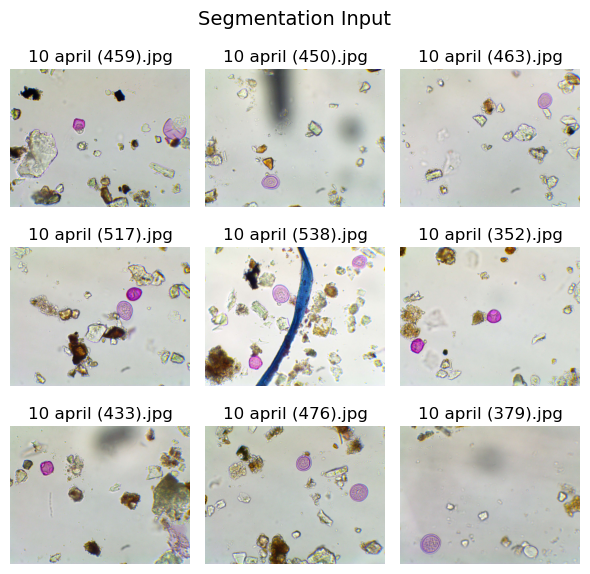

In [391]:
segmentation_input_dir = os.path.join(TEST_SAMPLES_ROOT, "april_10")
images = glob(os.path.join(segmentation_input_dir, "*.jpg"))

# Plot some samples
samples = images[0:9]
n = math.ceil(len(samples) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n*2, n*2))
for ax, img_path in zip(axs.flatten(), samples):
    image_rgb = io.imread(img_path)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path))
for ax in axs.flatten()[len(samples):]:
    ax.set_visible(False)
fig.suptitle('Segmentation Input', fontsize=14)
plt.tight_layout()
plt.show()

In [392]:
for image_path in tqdm(images):
    name = os.path.basename(image_path)
    score_threshold = 0.9
    mask_threshold = 0.9
    extract_mask_images(
        segmentation_model_path, segmentation_output_dir, image_path, score_threshold, mask_threshold, name
    )

  0%|          | 0/279 [00:00<?, ?it/s]

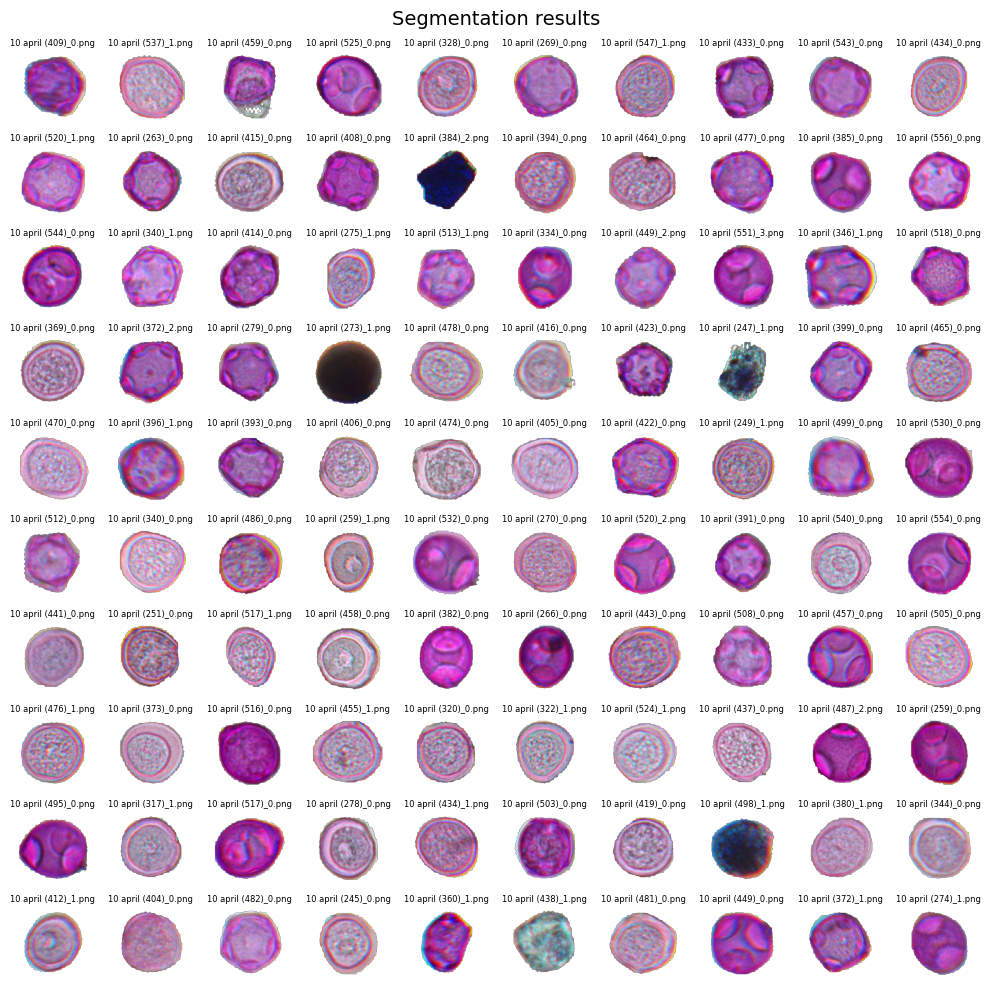

In [393]:
# Plot some objs
all_obj_images = glob(os.path.join(segmentation_output_dir,  "**", "*.png"), recursive=True)[0:100]
n = math.ceil(len(all_obj_images) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n, n))
for ax, img_path in zip(axs.flatten(), all_obj_images):
    image_rgb = io.imread(img_path)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path), fontsize=6)
for ax in axs.flatten()[len(all_obj_images):]:
    ax.set_visible(False)

fig.suptitle('Segmentation results', fontsize=14)
plt.tight_layout()
plt.show()

## Createing DB part

In [14]:
checkpoint_path = "/home/jovyan/Pollen-Analyzer/Classification/history/checkpoint-Adagrad-epoch=95-val_loss=0.22.ckpt"
classification_model = PollenOSCEmbeddingsModule.load_from_checkpoint(checkpoint_path)
classification_model.eval()


Using cache found in /home/jovyan/.cache/torch/hub/facebookresearch_dinov2_main
/home/jovyan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/jovyan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/jovyan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


PollenOSCEmbeddingsModule(
  (cac_loss): CACLoss()
  (model): OpenSetClassificationModel(
    (model): DinoVisionTransformer(
      (patch_embed): PatchEmbed(
        (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
        (norm): Identity()
      )
      (blocks): ModuleList(
        (0-11): 12 x NestedTensorBlock(
          (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
          (attn): MemEffAttention(
            (qkv): Linear(in_features=384, out_features=1152, bias=True)
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=384, out_features=384, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
          )
          (ls1): LayerScale()
          (drop_path1): Identity()
          (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=384, out_features=1536, bias=True)
            (act): GELU(approximate='none')
            (fc

In [15]:
OBJECTS_ROOT = r"/home/jovyan/pollen_dataset_2024_11_22/objects_clean"
known_classes = []
unknown_classes = ["Ambrosia"]
for c in os.listdir(OBJECTS_ROOT):
    if not os.path.isdir(os.path.join(OBJECTS_ROOT, c)):
        continue
    if c in unknown_classes:
        continue
    known_classes.append(c)

In [16]:
def save_class_to_indices(class_to_indices: dict, filename: str):
    with open(filename, "w") as f:
        json.dump(class_to_indices, f)


def load_class_to_indices(filename):
    with open(filename, "r") as f:
        return json.load(f)

def get_class(db, vector, k=5):
    neighbor_ids, distances = db.get_nns_by_vector(vector, k, include_distances=True)
    index_to_class = {}
    for class_name, indices in class_to_indices.items():
        for index in indices:
            index_to_class[index] = class_name
    neighbor_classes = [index_to_class[neighbor_id] for neighbor_id in neighbor_ids]
    # print(neighbor_classes)
    most_common_class = Counter(neighbor_classes).most_common(1)[0][0]
    return most_common_class

In [18]:
def erode(cycles, image):
    for _ in range(cycles):
         image = image.filter(ImageFilter.MinFilter(3))
    return image


def dilate(cycles, image):
    for _ in range(cycles):
         image = image.filter(ImageFilter.MaxFilter(3))
    return image
    
def smooth_edges(img):
    img_gray = img.convert("L")
    threshold = 0
    img_threshold = img_gray.point(
        lambda x: 255 if x > threshold else 0
    )
    step_1 = erode(3, img_threshold)
    mask = erode(1, step_1)
    mask = mask.convert("L")
    mask = mask.filter(ImageFilter.BoxBlur(3))
    blank = img.point(lambda _: 0)
    segmented = Image.composite(img, blank, mask)
    return segmented

In [ ]:
total_samples = 0
class_to_indices = {c: [] for c in known_classes}

f = 19  # Length of item vector that will be indexed
db = AnnoyIndex(f, "euclidean")
for c in tqdm(known_classes):
    images = glob(os.path.join(OBJECTS_ROOT, c, "*.png"))
    print(f"{len(images)} samples in the class {c}")

    for idx, img_path in enumerate(tqdm(images)):
        img = Image.open(img_path).convert("RGB")
        img = smooth_edges(img)
        features, _ = extract_features(img, classification_model)
        class_to_indices[c].append(total_samples)
        db.add_item(total_samples, features[0])
        total_samples += 1

print(f"Total samples: {total_samples}")
db.build(10)  # 10 trees

  0%|          | 0/18 [00:00<?, ?it/s]

103 samples in the class Alnus


  0%|          | 0/103 [00:00<?, ?it/s]

/opt/conda/lib/python3.11/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv2d(input, weight, bias, self.stride,


205 samples in the class Betula


...

  0%|          | 0/88 [00:00<?, ?it/s]

186 samples in the class Fraxinus


  0%|          | 0/186 [00:00<?, ?it/s]

Total samples: 2589


True

Alnus: 103
Betula: 205
Corylus: 145
Acer: 316
Chenopodiaceae: 150
Pinus: 67
Poaceae: 52
Apiaceae: 130
Rumex: 98
Salix: 233
Populus tremula: 210
Urtica: 42
Artemisia: 242
Picea: 96
Tilia: 113
Plantago: 113
Quercus: 88
Fraxinus: 186


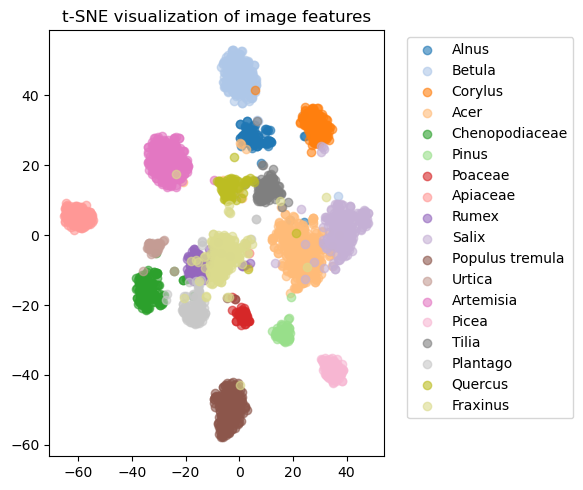

In [20]:
vectors = np.array(list(db.get_item_vector(i) for i in range(db.get_n_items())))
colors = matplotlib.colormaps["tab20"].colors

labels = [""] * vectors.shape[0]
for class_name, indices in class_to_indices.items():
    for index in indices:
        labels[index] = class_name
    print(f"{class_name}: {len(indices)}")

tsne = TSNE(n_components=2, random_state=42)
vectors_2d = tsne.fit_transform(vectors)

plt.figure(figsize=(6, 5))
for i, (class_name, indices) in enumerate(class_to_indices.items()):
    mask = np.isin(range(vectors.shape[0]), indices)
    plt.scatter(
        vectors_2d[mask, 0],
        vectors_2d[mask, 1],
        label=class_name,
        color=colors[i],
        alpha=0.6,
    )

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("t-SNE visualization of image features")
plt.tight_layout()
plt.show()

### Test DB

In [21]:
counter = 0
for test_case in test_ds:
    c = test_case[0]
    vector = test_case[1]
    pred_class = get_class(db, vector, 5)
    if pred_class == c:
        counter += 1
print(len(test_ds), counter)

NameError: name 'test_ds' is not defined

## Classification part

In [22]:
# classification by model
def distance_to_scores(distances):
    softmax = torch.nn.Softmax(dim = 1)
    softmin = softmax(-distances)
    invScores = 1-softmin
    scores = distances*invScores
    return scores

def scores_to_class(scores: torch.Tensor, threshold):
    candidate = scores.argmin(dim=1)
    pred_candidate = torch.where(scores[range(scores.shape[0]), candidate.T] < threshold, candidate, -1)
    return pred_candidate

label_map = {0: 'Alnus',
     1: 'Betula',
     2: 'Corylus',
     3: 'Acer',
     4: 'Chenopodiaceae',
     5: 'Pinus',
     6: 'Poaceae',
     7: 'Apiaceae',
     8: 'Rumex',
     9: 'Salix',
     10: 'Populus tremula',
     11: 'Urtica',
     12: 'Artemisia',
     13: 'Picea',
     14: 'Tilia',
     15: 'Plantago',
     16: 'Quercus',
     17: 'Fraxinus',
     -1: 'Unknown'}

In [23]:
pred_labels = {}
embeddings_data = []

all_obj_images = glob(os.path.join(segmentation_output_dir,  "**", "*.png"), recursive=True)
for img_path in tqdm(all_obj_images):
    img = Image.open(img_path).convert("RGB")
    img = smooth_edges(img)
    features, pred_distances = extract_features(img, classification_model)
    vector = features[0]
    # classification by model
    # scores = distance_to_scores(pred_distances)
    # prediction = scores_to_class(scores, 4.5)
    # predict_str = [label_map[l.item()] for l in prediction.cpu()]
    # pred_class = predict_str[0]
    # classification with DB
    pred_class = get_class(db, vector, 5)
    if pred_class in pred_labels:
        pred_labels[pred_class] = pred_labels[pred_class] + 1
    else:
        pred_labels[pred_class] = 1
    embeddings_data.append(vector.cpu())

NameError: name 'segmentation_output_dir' is not defined

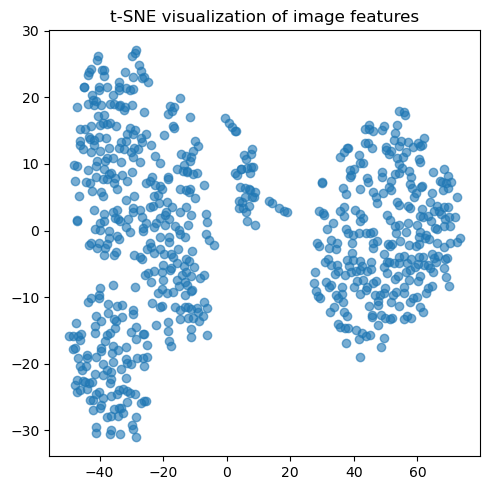

In [39]:
# TSNE
vectors = np.array(embeddings_data)
tsne = TSNE(n_components=2, random_state=42, perplexity=20, metric="euclidean", n_iter=2000, n_jobs=-1, early_exaggeration=12)#cosine
vectors_2d = tsne.fit_transform(vectors)

plt.figure(figsize=(5, 5))
plt.scatter(vectors_2d[:,0], vectors_2d[:,1], alpha=0.6)

plt.title("t-SNE visualization of image features")
plt.tight_layout()
plt.show()

### Compare with sheet data

In [27]:
TEST_SAMPLES_ROOT = "/home/jovyan/pollen_dataset_2024_11_22/Sample"
excel_path = os.path.join(TEST_SAMPLES_ROOT, "manual_analysis.xlsx")
df = pd.ExcelFile(excel_path)

In [28]:
def calculate_confusion_matrix(y_true, y_pred, classes):
    confusion_matrices = {}
    
    for cls in classes:
        tp = 0
        if y_pred.get(cls, 0) > 0:
            if y_pred.get(cls, 0) <= y_true.get(cls, 0):
                tp = y_pred.get(cls, 0)
            else:
                tp = y_true.get(cls, 0)            
        fp = 0
        if y_pred.get(cls, 0) > 0:
            if y_pred.get(cls, 0) > y_true.get(cls, 0):
                fp = y_pred.get(cls, 0) - y_true.get(cls, 0)
        fn = 0
        if y_pred.get(cls, 0) <= y_true.get(cls, 0):
            fn = y_true.get(cls, 0) - y_pred.get(cls, 0)
        
        tn = sum(
            y_pred.get(other_cls, 0) 
            for other_cls in classes if other_cls != cls
        )
        confusion_matrices[cls] = {"TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}
    return pd.DataFrame(confusion_matrices).T

In [408]:
def plot_confusion_matrix(df: pd.DataFrame, subtitle: str = ""):
    plt.figure(figsize=(6, 4))
    sns.heatmap(df, annot=True, fmt="d", cmap="Blues", cbar=True, linewidths=0.5)
    if len(subtitle) > 0:
        plt.title("Confusion Matrix\n" + subtitle)
    else:
        plt.title("Confusion Matrix")
    plt.ylabel("Class")
    plt.tight_layout()
    plt.show()

In [409]:
sheet_data = df.parse(df.sheet_names[0])
sheet_data = sheet_data.rename(columns={"Populus": "Populus tremula"})
sheet_data.head(4)

,date,Corylus,Populus tremula,Alnus,Betula,Urtica,Salix,Chenopodiaceae,Pinus,Artemisia,Unknown
0,april 10,72.0,178.0,150.0,6.0,1.0,0.0,0.0,0.0,0.0,6.0
1,april 12,30.0,82.0,61.0,5.0,0.0,0.0,0.0,0.0,0.0,3.0
2,april 16,22.0,61.0,50.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
3,april 18,57.0,149.0,166.0,13.0,0.0,4.0,1.0,0.0,0.0,6.0


In [410]:
def test_sample_data(true_labels, pred_labels, all_classes):
    print("---Sample test---")
    print(f"True Total objets: {sum(true_labels.values())}, data: {true_labels}")
    print("-" * 10)
    print(f"Pred Total objets: {sum(pred_labels.values())}, data: {pred_labels}")
    confusion_matrices_df = calculate_confusion_matrix(true_labels, pred_labels, all_classes)
    plot_confusion_matrix(confusion_matrices_df.iloc[:, 0:3])
    for k in true_labels.keys():
        if true_labels[k] != 0:
            print(k, round(confusion_matrices_df["TP"].to_dict().get(k, 0) / true_labels[k], 3))

/tmp/ipykernel_89210/3485841325.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  segmentation_output_dir = "segmentation_output_" + str(sheet_data.iloc[i][0].replace(" ", "_"))


  0%|          | 0/377 [00:00<?, ?it/s]

---Sample test---
True Total objets: 413.0, data: {'Corylus': 72.0, 'Populus tremula': 178.0, 'Alnus': 150.0, 'Betula': 6.0, 'Urtica': 1.0, 'Salix': 0.0, 'Chenopodiaceae': 0.0, 'Pinus': 0.0, 'Artemisia': 0.0, 'Unknown': 6.0}
----------
Pred Total objets: 377, data: {'Acer': 63, 'Populus tremula': 131, 'Fraxinus': 35, 'Quercus': 8, 'Betula': 42, 'Alnus': 51, 'Chenopodiaceae': 13, 'Salix': 3, 'Picea': 1, 'Artemisia': 9, 'Poaceae': 13, 'Rumex': 3, 'Apiaceae': 3, 'Plantago': 2}


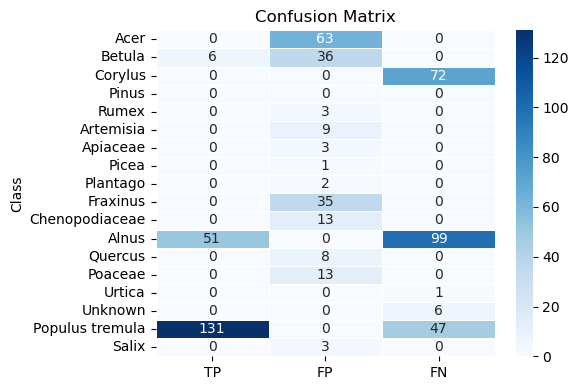

Corylus 0.0
Populus tremula 0.736
Alnus 0.34
Betula 1.0
Urtica 0.0
Unknown 0.0


In [414]:
for i in range(1):
    segmentation_output_dir = "segmentation_output_" + str(sheet_data.iloc[i][0].replace(" ", "_"))
    true_labels = sheet_data.iloc[i][1:].to_dict()
    pred_labels = {}

    all_obj_images = glob(os.path.join(segmentation_output_dir,  "**", "*.png"), recursive=True)
    for img_path in tqdm(all_obj_images):
        img = Image.open(img_path).convert("RGB")
        # img = smooth_contour(Image.open(img_path)).convert("RGB")
        img = smooth_edges(img)
        features, pred_distances = extract_features(img, classification_model)
        vector = features[0]
        # classification by model
        # scores = distance_to_scores(pred_distances)
        # prediction = scores_to_class(scores, 4.5)
        # predict_str = [label_map[l.item()] for l in prediction.cpu()]
        # pred_class = predict_str[0]
        # classification with DB
        pred_class = get_class(db, vector, 5)
        if pred_class in pred_labels:
            pred_labels[pred_class] = pred_labels[pred_class] + 1
        else:
            pred_labels[pred_class] = 1
    all_classes = set(true_labels.keys()).union(set(pred_labels.keys()))
    test_sample_data(true_labels, pred_labels, all_classes)

## Research

In [618]:
features, pred_distances = extract_features(img, classification_model)
vector = features[0]
# classification by model
scores = distance_to_scores(pred_distances)
prediction = scores_to_class(scores, 4.5)
predict_str = [label_map[l.item()] for l in prediction.cpu()]
pred_class = predict_str[0]
print(pred_class)
# classification with DB
pred_class = get_class(db, vector, 7)
print(pred_class)

Acer
['Acer', 'Acer', 'Acer', 'Acer', 'Acer', 'Fraxinus', 'Acer']
Acer


In [619]:
features, pred_distances = extract_features(smooth_img, classification_model)
vector = features[0]
# classification by model
scores = distance_to_scores(pred_distances)
prediction = scores_to_class(scores, 4.5)
predict_str = [label_map[l.item()] for l in prediction.cpu()]
pred_class = predict_str[0]
print(pred_class)
# classification with DB
pred_class = get_class(db, vector, 7)
print(pred_class)

Betula
['Acer', 'Fraxinus', 'Salix', 'Alnus', 'Salix', 'Salix', 'Salix']
Salix


In [45]:
img1_upd = "/home/jovyan/git/Pollen-Analyzer/Sample_1_(99)_0.png"
img1 = "/home/jovyan/git/Pollen-Analyzer/Sample_1 (99)_0.png"
test_imgs = [img1_upd, img1]
for img_path in test_imgs:
    img = Image.open(img_path).convert("RGB")
    img = smooth_edges(img)
    features, pred_distances = extract_features(img, classification_model)
    vector = features[0]
    # classification with DB
    pred_class = get_class(db, vector, 5)
    print(pred_class)

Alnus
Acer


In [46]:
img1_upd = "/home/jovyan/git/Pollen-Analyzer/Sample_1_(105)_0_(1).png"
img1 = "/home/jovyan/git/Pollen-Analyzer/Sample_1 (105)_0 (1).png"
test_imgs = [img1_upd, img1]
for img_path in test_imgs:
    img = Image.open(img_path).convert("RGB")
    img = smooth_edges(img)
    features, pred_distances = extract_features(img, classification_model)
    vector = features[0]
    # classification with DB
    pred_class = get_class(db, vector, 5)
    print(pred_class)

Alnus
Tilia


In [383]:
def add_padding(img_array, padding=10, fill_value=0):
    """
    Добавляет прозрачные отступы со всех сторон изображения (NumPy массив).

    :param img_array: Изображение в формате NumPy массива (H x W x C).
    :param padding: Количество пустых пикселей со всех сторон (по умолчанию 10).
    :param fill_value: Значение, которым заполняются пустые пиксели (по умолчанию 0 — прозрачный фон).
    :return: NumPy массив с добавленными прозрачными отступами со всех сторон.
    """
    # Добавляем отступы со всех сторон
    padded_image = np.pad(
        img_array,
        pad_width=((padding, padding), (padding, padding), (0, 0)),  # Отступы для height, width, channels
        mode='constant',  # Режим заполнения: константное значение
        constant_values=fill_value  # Значение для заполнения (0 для прозрачного фона)
    )
    
    return padded_image

def smooth_contour(img):
    img = np.array(img)
    kernel_size = int(img.shape[0] / 2.6)
    erode_count = int(kernel_size / 2.2)
    img = add_padding(img, kernel_size)
    # extract alpha channel
    alpha = img[:,:,3]

    # get largest contours
    contours = cv2.findContours(alpha, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = contours[0] if len(contours) == 2 else contours[1]
    big_contour = max(contours, key=cv2.contourArea)
    
    # smooth contour
    peri = cv2.arcLength(big_contour, True)
    big_contour = cv2.approxPolyDP(big_contour, 0.001 * peri, True)
    
    # draw white filled contour on black background
    contour_img = np.zeros_like(alpha)
    cv2.drawContours(contour_img, [big_contour], 0, 255, -1)
    
    # apply dilate to connect the white areas in the alpha channel
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    dilate = cv2.morphologyEx(contour_img, cv2.MORPH_DILATE, kernel)
    mask = Image.fromarray(dilate)

    img = Image.fromarray(img)
    img_gray = img.convert("L")
    threshold = 0
    img_threshold = img_gray.point(
        lambda x: 255 if x > threshold else 0
    )
    mask = erode(erode_count, mask)
    mask = mask.filter(ImageFilter.BoxBlur(3))
    blank = img.point(lambda _: 0)
    segmented = Image.composite(img, blank, mask)
    return segmented

In [384]:
# Corylus	Populus	Alnus	Betula	Urtica

  0%|          | 0/10 [00:00<?, ?it/s]

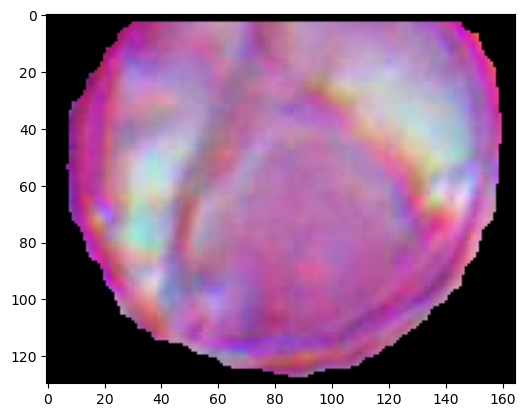

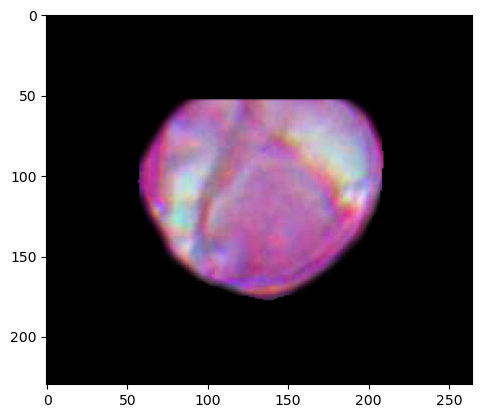

['Acer', 'Alnus', 'Acer', 'Apiaceae', 'Salix']
Acer


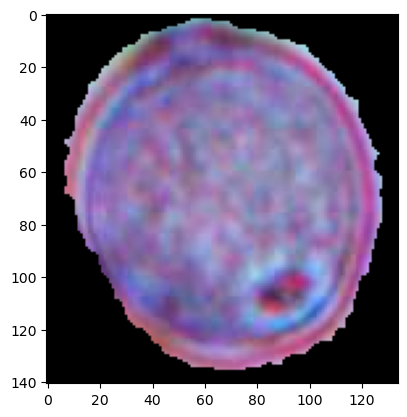

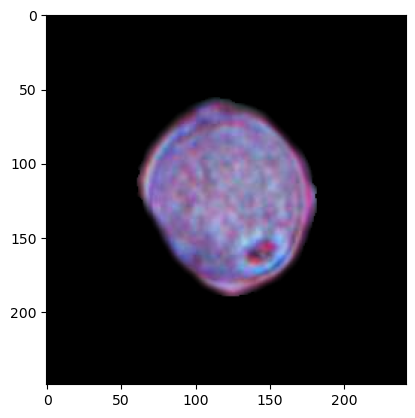

['Fraxinus', 'Fraxinus', 'Fraxinus', 'Fraxinus', 'Fraxinus']
Fraxinus


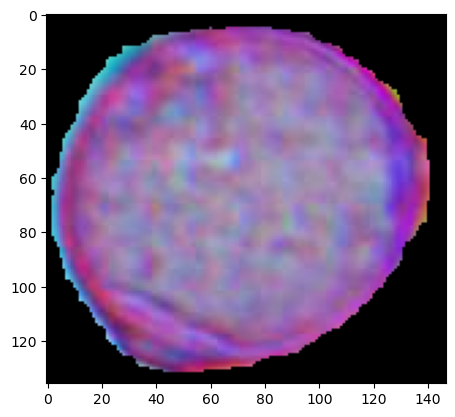

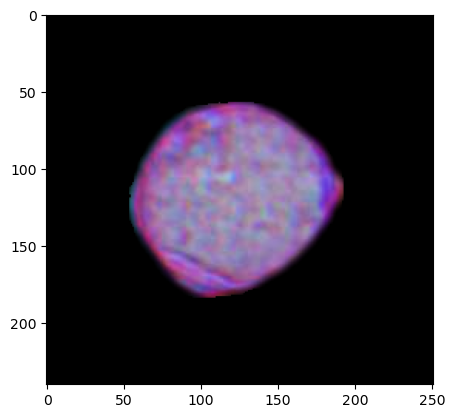

['Fraxinus', 'Fraxinus', 'Fraxinus', 'Fraxinus', 'Fraxinus']
Fraxinus


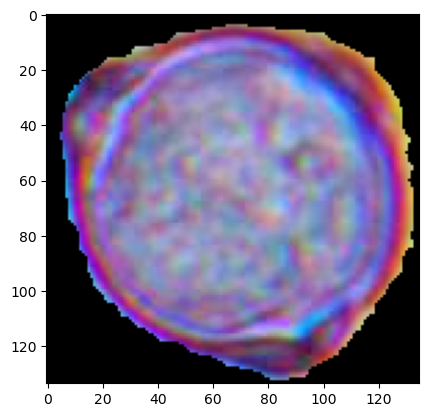

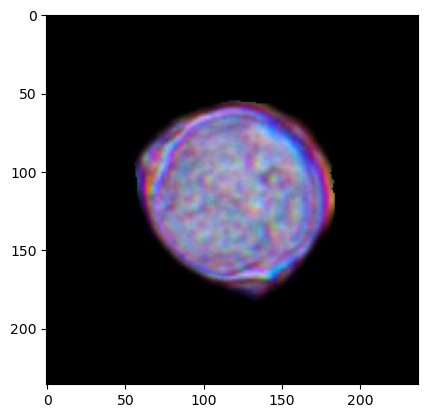

['Artemisia', 'Artemisia', 'Artemisia', 'Artemisia', 'Artemisia']
Artemisia


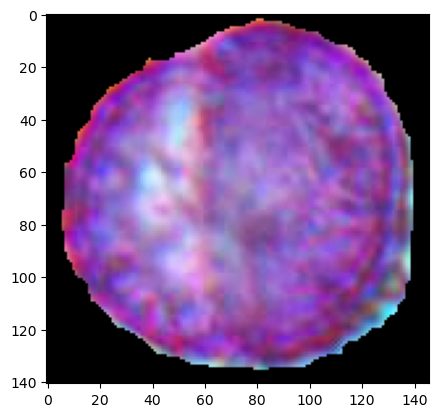

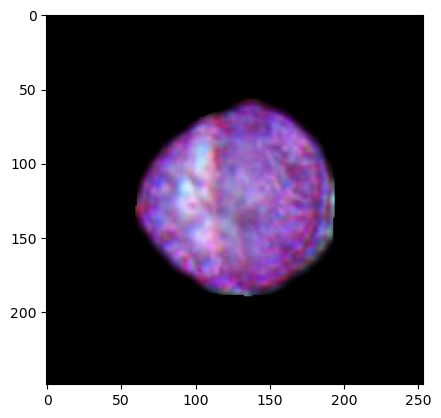

['Acer', 'Acer', 'Fraxinus', 'Salix', 'Salix']
Acer


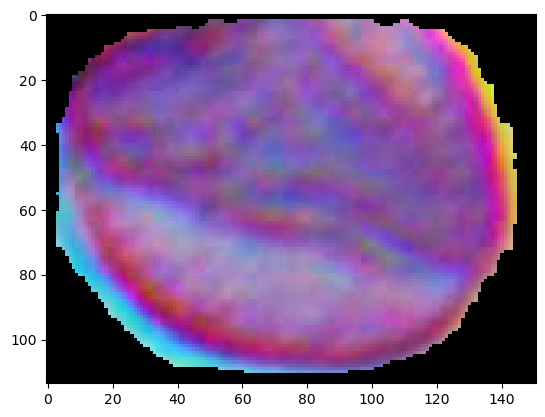

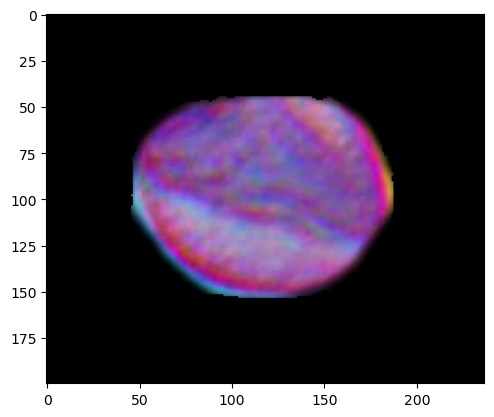

['Acer', 'Apiaceae', 'Salix', 'Salix', 'Artemisia']
Salix


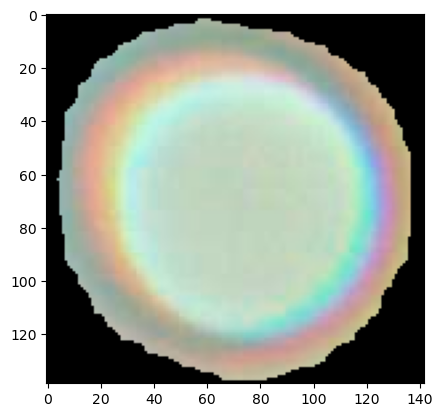

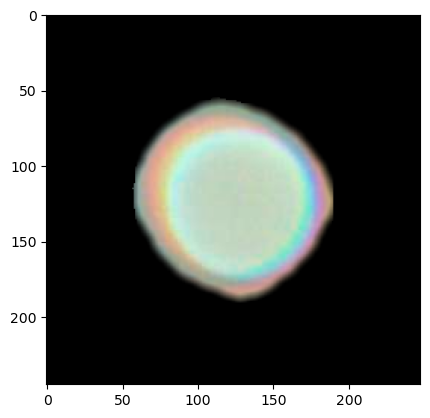

['Artemisia', 'Artemisia', 'Artemisia', 'Artemisia', 'Artemisia']
Artemisia


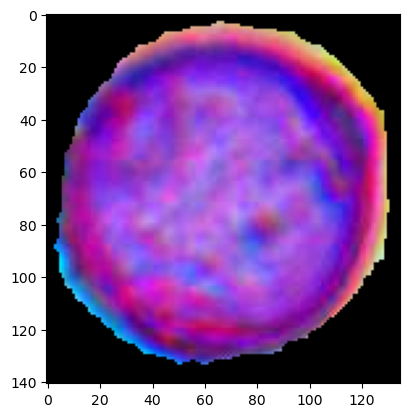

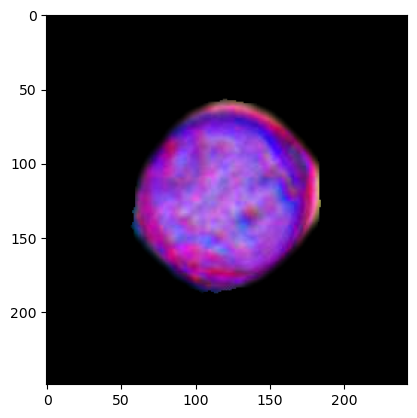

['Fraxinus', 'Fraxinus', 'Fraxinus', 'Fraxinus', 'Fraxinus']
Fraxinus


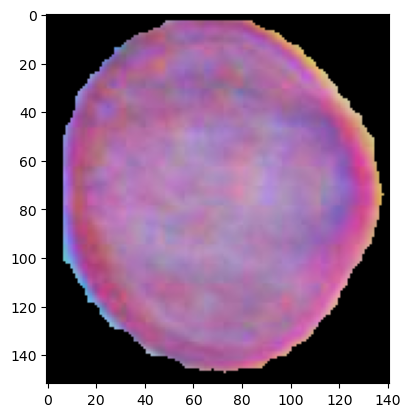

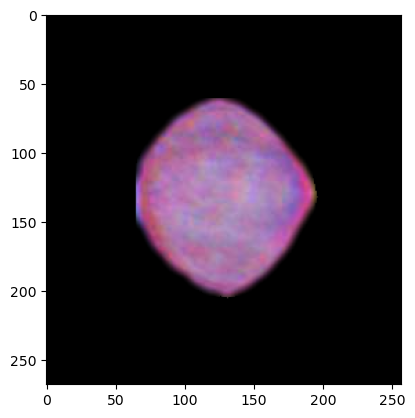

['Fraxinus', 'Salix', 'Fraxinus', 'Salix', 'Acer']
Fraxinus


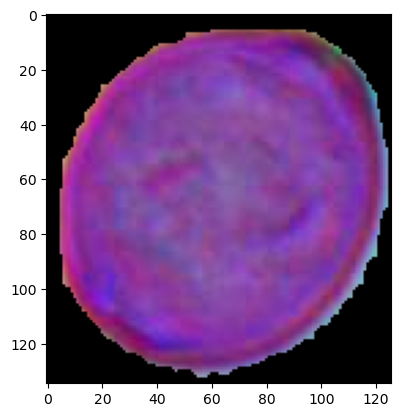

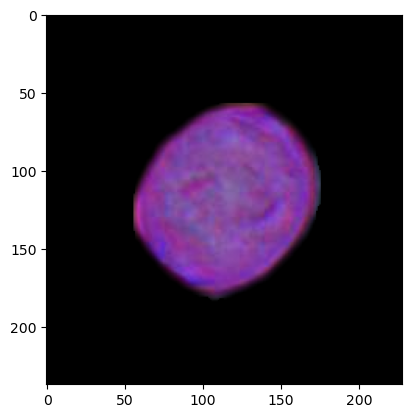

['Alnus', 'Alnus', 'Alnus', 'Alnus', 'Alnus']
Alnus


In [388]:
segmentation_output_dir = "segmentation_output_" + str(i+1)
true_labels = sheet_data.iloc[i][1:].to_dict()
pred_labels = {}

all_obj_images = glob(os.path.join(segmentation_output_dir,  "**", "*.png"), recursive=True)[10:20]
for img_path in tqdm(all_obj_images):
    # img = Image.open(img_path).convert("RGB")
    plt.imshow(Image.open(img_path).convert("RGB"))
    plt.show()
    img = smooth_contour(Image.open(img_path)).convert("RGB")
    plt.imshow(img)
    plt.show()
    features, pred_distances = extract_features(img, classification_model)
    vector = features[0]
    # classification with DB
    pred_class = get_class(db, vector, 5)
    print(pred_class)